# ``meshlab`` - Tutorial 5

**Airfoil with a translated slat and flap**


## 1. Import packages
---


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from meshlab.core import Mesh, Curve, Contour, Front
from meshlab.operations import (
    insert_contour, initialize_front, compute_normals,
    smooth_normals, advance_front, split_curve,
)
from meshlab.utils import plot_mesh
from meshlab.export import export_mesh

## 2. Geometries definition
---


Original NACA 2412 airfoil


In [3]:
airfoil = np.loadtxt("./data/NACA-2412.dat")

Surface points

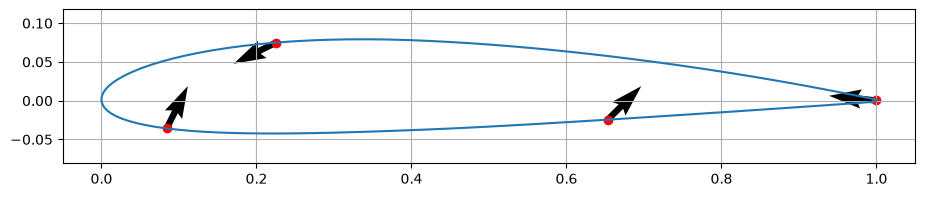

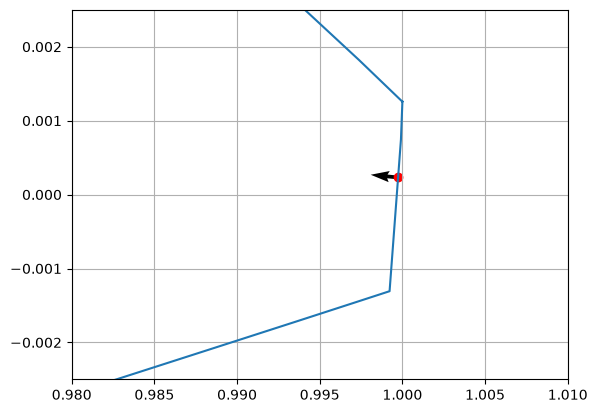

In [43]:
from numpy.typing import ArrayLike
def unit_vector(v: ArrayLike) -> np.ndarray:
    """Return a unit vector based on v"""
    v = np.asarray(v)
    return v / np.linalg.norm(v)

v1 = 40
v2 = 70
v3 = 95
v4 = 121

t1 = unit_vector([-1, -0.5])
t2 = unit_vector([0.5, 1])
t3 = unit_vector([1, 1])
t4 = unit_vector([-1, 0.1])

plt.figure(figsize=(11, 2))
plt.plot(airfoil[:, 0], airfoil[:, 1])

plt.quiver(airfoil[v1, 0], airfoil[v1, 1], t1[0], t1[1])
plt.quiver(airfoil[v2, 0], airfoil[v2, 1], t2[0], t2[1])
plt.quiver(airfoil[v3, 0], airfoil[v3, 1], t3[0], t3[1])
plt.quiver(airfoil[v4, 0], airfoil[v4, 1], t4[0], t4[1])

plt.scatter(airfoil[v1, 0], airfoil[v1, 1], color="red")
plt.scatter(airfoil[v2, 0], airfoil[v2, 1], color="red")
plt.scatter(airfoil[v3, 0], airfoil[v3, 1], color="red")
plt.scatter(airfoil[v4, 0], airfoil[v4, 1], color="red")

plt.axis("equal")

plt.grid()

plt.figure()
plt.plot(airfoil[:, 0], airfoil[:, 1])

plt.quiver(airfoil[v4, 0], airfoil[v4, 1], t4[0], t4[1])

plt.scatter(airfoil[v1, 0], airfoil[v1, 1], color="red")
plt.scatter(airfoil[v2, 0], airfoil[v2, 1], color="red")
plt.scatter(airfoil[v3, 0], airfoil[v3, 1], color="red")
plt.scatter(airfoil[v4, 0], airfoil[v4, 1], color="red")

plt.xlim([0.98, 1.01])
plt.ylim([-0.0025, 0.0025])
plt.grid()

plt.show()

In [32]:
import numpy as np


def split_curve(
    curve: np.ndarray,
    n1: int,
    t1: np.ndarray,
    n2: int,
    t2: np.ndarray,
    r: float,
) -> list[np.ndarray]:
    # Normaliza as direções
    t1 = np.asarray(t1, dtype=float).reshape(2)
    t2 = np.asarray(t2, dtype=float).reshape(2)
    t1 /= np.linalg.norm(t1)
    t2 /= np.linalg.norm(t2)

    # Passo médio local
    diff_curve = np.diff(curve, axis=0)                # (n-1, 2)
    delta_s = np.linalg.norm(diff_curve, axis=1)       # (n-1,)
    ds = 0.5 * (delta_s[n1] + delta_s[n2]) / 2

    P1 = curve[n1]                                      # (2,)
    P2 = curve[n2]                                      # (2,)

    # Interseção das retas P1 + s·t1  e  P2 + u·t2
    A = np.column_stack((t1, -t2))
    b = P2 - P1
    try:
        s, u = np.linalg.solve(A, b)
    except np.linalg.LinAlgError:
        raise ValueError("As retas definidas por t1 e t2 são paralelas.")

    if s < 0 or u < 0:
        raise ValueError("As retas não se cruzam no sentido positivo de t1 e t2.")

    P = P1 + s * t1

    # Ângulo interno do canto
    cos_theta = np.clip(np.dot(t1, t2), -1.0, 1.0)
    theta = np.arccos(cos_theta)
    if theta < 1e-12 or theta > np.pi - 1e-12:
        raise ValueError("Ângulo degenerado; filete impossível.")

    d = r / np.tan(theta / 2.0)
    if s < d or u < d:
        raise ValueError("O raio r é grande demais para os segmentos dados.")

    T1 = P - d * t1
    T2 = P - d * t2

    # Centro da circunferência
    b_vec = (-t1) + (-t2)
    b_vec /= np.linalg.norm(b_vec)
    C = P + (r / np.sin(theta / 2.0)) * b_vec

    # Sentido do arco
    cross = t1[0] * t2[1] - t1[1] * t2[0]
    direction = -np.sign(cross)
    if direction == 0:
        direction = 1.0

    phi = np.pi - theta   # ângulo central do arco

    # ---------- discretização: número de elementos ≈ L / ds ----------
    def n_elements(L, step):
        # arredonda para o inteiro mais próximo e garante pelo menos 1
        return max(1, int(L / step + 0.5))

    def points_on_segment(A_pt, B_pt, step):
        v = B_pt - A_pt
        L = np.linalg.norm(v)
        if L < 1e-12:
            return np.empty((0, 2))
        k = n_elements(L, step)
        tt = np.linspace(0.0, 1.0, k + 1)[1:]           # exclui A_pt
        return A_pt[None, :] + v[None, :] * tt[:, None]  # (k, 2)

    def points_on_arc(C_pt, Ta, Tb, radius, step, direction, phi):
        a1 = np.arctan2(Ta[1] - C_pt[1], Ta[0] - C_pt[0])
        a2 = a1 + direction * phi
        L = radius * phi
        if L < 1e-12:
            return np.empty((0, 2))
        k = n_elements(L, step)
        angles = np.linspace(a1, a2, k + 1)[1:]          # exclui Ta
        pts = np.empty((k, 2))
        pts[:, 0] = C_pt[0] + radius * np.cos(angles)
        pts[:, 1] = C_pt[1] + radius * np.sin(angles)
        pts[-1] = Tb                                     # fecha exatamente em Tb
        return pts

    # ---------- novo caminho: P1 → T1 → arco → T2 → P2 ----------
    new_path_parts = [P1[None, :]]
    seg1 = points_on_segment(P1, T1, ds)
    if seg1.shape[0] > 0:
        new_path_parts.append(seg1)
    arc = points_on_arc(C, T1, T2, r, ds, direction, phi)
    if arc.shape[0] > 0:
        new_path_parts.append(arc)
    seg2 = points_on_segment(T2, P2, ds)
    if seg2.shape[0] > 0:
        new_path_parts.append(seg2)

    new_path = np.concatenate(new_path_parts, axis=0)
    new_path[0] = P1
    new_path[-1] = P2

    # ---------- trechos da curva original ----------
    def get_curve_segment(curve, i, j):
        if i <= j:
            return curve[i:j + 1]
        return np.concatenate((curve[i:], curve[1:j + 1]), axis=0)

    partA = get_curve_segment(curve, n1, n2)   # n1 → n2 (ordem original)
    partB = get_curve_segment(curve, n2, n1)   # n2 → n1 (ordem original)

    # ---------- duas curvas fechadas ----------
    curve1 = np.concatenate((partB, new_path[1:]),      axis=0)  # n2→n1 + (n1→n2 novo)
    curve2 = np.concatenate((partA, new_path[-2::-1]),  axis=0)  # n1→n2 + (n2→n1 novo)

    return [curve1, curve2]

In [50]:
c1, c2 = split_curve(airfoil, v1, t1, v2, t2, 0.1)
c1 = c1 + np.array([[0.1, 0]])

In [54]:
print(c1.shape)

(114, 2)


In [ ]:
plt.figure()

plt.plot(c1[:, 0], c1[:, 1])
plt.scatter(c1[70, 0], c1[70, 1])

plt.plot(c2[:, 0], c2[:, 1])

plt.axis("equal")
plt.grid()
plt.show()

IndexError: index 701 is out of bounds for axis 0 with size 114

Error in callback <function _draw_all_if_interactive at 0x7d827b3d9bc0> (for post_execute), with arguments args (),kwargs {}:


Slat, main airfoil and flap


In [ ]:
# The cut is determined by two surface nodes, two inward directions and a radius
original_curve = Curve("original_airfoil", np.vstack((airfoil_points, airfoil_points[0])))
main_curve, flap_curve = split_curve(
    original_curve,
    start_index=flap_start_index,
    end_index=flap_end_index,
    start_direction=flap_start_direction,
    end_direction=flap_end_direction,
    radius=flap_cut_radius,
)

# Extract the shared cut from the end of the first returned contour
surface_count = (flap_end_index - flap_start_index) % len(airfoil_points) + 1
flap_cut_points = main_curve.points[surface_count - 1:][::-1]

# Keep the slat cut unchanged; discretize the curved flap cut more finely
slat_points = crop_airfoil(airfoil_points, xmin, slat_cut, max_spacing) + slat_offset
main_points = crop_airfoil(main_curve.points[:-1], slat_cut, xmax, 0.004 * chord)
flap_points = crop_airfoil(flap_curve.points[:-1], xmin, xmax, 0.004 * chord) + flap_offset

slat = Contour("slat", [Curve("slat_wall", slat_points)])
main_airfoil = Contour("main_airfoil", [Curve("main_wall", main_points)])
flap = Contour("flap", [Curve("flap_wall", flap_points)])

Flap cut before translation


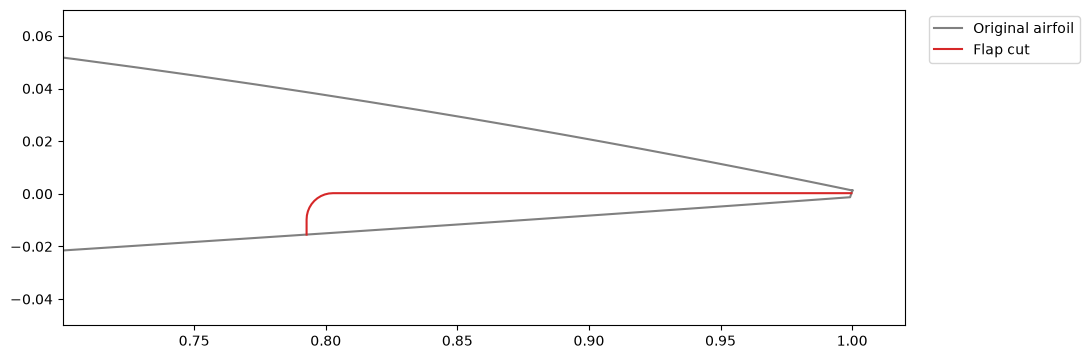

In [ ]:
figure, ax = plt.subplots(figsize=(11, 5))
outline = np.vstack((airfoil_points, airfoil_points[0]))
ax.plot(outline[:, 0], outline[:, 1], color="0.5", label="Original airfoil")
ax.plot(flap_cut_points[:, 0], flap_cut_points[:, 1], color="tab:red", label="Flap cut")
ax.set_xlim(xmax - 0.3 * chord, xmax + 0.02 * chord)
ax.set_ylim(-0.05 * chord, 0.07 * chord)
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()
plt.show()

## 3. Creating mesh surfaces
---


In [ ]:
mesh = Mesh(dim=2, vertices_capacity=5000, cells_capacity=5000)
insert_contour(mesh, slat)
insert_contour(mesh, main_airfoil)
insert_contour(mesh, flap)

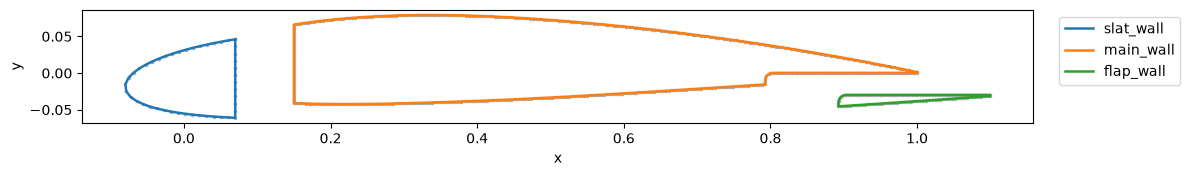

In [ ]:
figure, ax = plot_mesh(mesh, show=False)

figure.set_size_inches(12, 5)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()

plt.show()

## 4. Initialize fronts
---


In [ ]:
# Thin layers leave the gaps open for the residual Gmsh mesh
num_layers = 8
height = 0.0004 * chord
growth_rate = 1.10
smooth_steps = 3
relaxation = 0.5

slat_front = Front("slat_front", int_dtype=mesh.int_dtype)
main_front = Front("main_front", int_dtype=mesh.int_dtype)
flap_front = Front("flap_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, slat_front, curves=["slat_wall"])
initialize_front(mesh, main_front, curves=["main_wall"])
initialize_front(mesh, flap_front, curves=["flap_wall"])
fronts = [slat_front, main_front, flap_front]

## 5. Growing boundary layers
---


In [ ]:
h = height
for _ in range(num_layers):
    for front in fronts:
        normals = compute_normals(mesh, front, method="bisector")
        for _ in range(smooth_steps):
            normals, _ = smooth_normals(mesh, front, normals, relaxation)
        advance_front(mesh, front, normals, h)
    h *= growth_rate

Visualize mesh


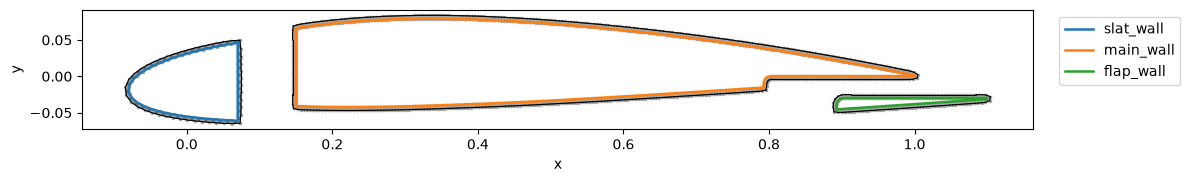

In [ ]:
figure, ax = plot_mesh(mesh, show=False)

figure.set_size_inches(12, 5)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()

plt.show()

## 6. Circular domain
---


In [ ]:
farfield_radius = 5.0 * chord
farfield_points = 100
center = np.array([xmin + 0.5 * chord, 0.0])

# External contour in a clockwise direction
angles = np.linspace(0.0, -2.0 * np.pi, farfield_points, endpoint=False)
points = center + farfield_radius * np.column_stack((np.cos(angles), np.sin(angles)))
points = np.vstack((points, points[0]))

farfield = Contour("outer_domain", [Curve("freestream", points)])
insert_contour(mesh, farfield)

## 7. Generate and export the Gmsh mesh
---


In [ ]:
thickness = 0.1 * chord
mesh_size = 0.3 * chord
show_gmsh = False             # True opens the interactive Gmsh window
filename = tutorial_dir / "results/slat-airfoil-flap.msh"
filename.parent.mkdir(parents=True, exist_ok=True)

In [ ]:
# Preserve the three layer meshes and fill the remaining region, including gaps
export_mesh(
    mesh,
    fronts=fronts,
    filename=filename,
    mode="planar",
    thickness=thickness,
    mesh_size=mesh_size,
    show=show_gmsh,
)

print(filename)

/home/user/Documentos/GitHub/meshlab/tutorials/results/slat-airfoil-flap.msh


## 8. Convert to OpenFOAM
---


In [ ]:
# Run in a terminal using a prepared OpenFOAM case:
# Set writePrecision to 16 in system/controlDict before conversion.
# gmshToFoam /path/to/tutorials/results/slat-airfoil-flap.msh
# Set frontAndBack to empty in constant/polyMesh/boundary and the field files.
# checkMesh -allTopology -allGeometry